# 🏛️ Pretrained Models, ImageNet & ILSVRC

## 1. Pretrained Models

**Pretrained Models** are neural networks already trained on large datasets (e.g., ImageNet). Their learned weights and biases can be reused for new tasks.

**Why use them?**
- Reduces training time and computational cost.
- Requires less labelled data.
- Reuses learned features like edges, textures and shapes.
- Provides better initialization than random weights.

**Transfer Learning:** Reusing a pretrained model for a different but related task.

---

## 2. ImageNet Dataset

A large-scale image database created in 2006 by **Dr. Fei-Fei Li and her team**.

- 14+ million labelled images.
- 20,000+ categories (synsets).
- 1+ million images with bounding-box annotations.
- Annotations collected through crowdsourcing (Amazon Mechanical Turk).

**Synset:** A group of synonymous words representing a particular concept in WordNet.

---

## 3. ILSVRC

**ImageNet Large Scale Visual Recognition Challenge** (started in 2010).

A computer vision competition using an ImageNet subset.

- ~1.2 million training images.
- 1,000 object classes.
- Evaluated image classification models.

**Top-5 Error Rate:** Percentage of images where the actual class is absent from the model's top 5 predictions.

---

## 4. Evolution of CNN Architectures

| Year | Architecture | Key Contribution | Top-5 Error |
|---|---|---|---:|
| 2012 | AlexNet | ReLU, Dropout, GPU training | 16.4% |
| 2013 | ZFNet | Feature map visualization | 11.7% |
| 2014 | VGG-16 | Small 3×3 filters, deeper networks | ~7.3% |
| 2014 | GoogLeNet | Inception modules, 1×1 convolutions | ~6.7% |
| 2015 | ResNet | Skip/Residual connections | 3.5% |

### Important Concepts

- **AlexNet:** Popularized deep CNNs for large-scale image classification.
- **ZFNet:** Improved CNN architecture using feature visualization.
- **VGG:** Uses repeated 3×3 convolution and 2×2 max-pooling.
- **GoogLeNet:** Uses parallel convolutions through Inception modules.
- **ResNet:** Uses residual connections to enable training deeper networks.

Residual Connection:

\[
y = F(x) + x
\]

Where \(x\) is the input and \(F(x)\) is the learned transformation.

---

## 5. Pretrained Models in Keras

Keras provides pretrained CNN architectures through `keras.applications`.

| Model | Size | Parameters | Top-1 | Top-5 |
|---|---:|---:|---:|---:|
| VGG16 | 528 MB | 138.3M | 71.3% | 90.1% |
| ResNet50 | 98 MB | 25.6M | 74.9% | 92.1% |
| InceptionV3 | 92 MB | 23.8M | 77.9% | 93.7% |
| MobileNetV2 | 14 MB | 3.5M | 71.3% | 90.1% |

### Key Differences

- **VGG16:** Simple but computationally expensive.
- **ResNet50:** Uses residual connections.
- **InceptionV3:** Uses parallel multi-scale convolutions.
- **MobileNetV2:** Lightweight, suitable for mobile devices.

---

## 6. Key Takeaways

1. Pretrained models save training time and computational resources.
2. ImageNet provides large-scale labelled image data.
3. ILSVRC accelerated CNN architecture development.
4. ResNet introduced residual connections.
5. Keras provides pretrained models through `keras.applications`.
6. Pretrained models are widely used in Transfer Learning.

In [1]:
import numpy as np 
from tensorflow.keras.applications.resnet50 import ResNet50, preprocess_input, decode_predictions
from tensorflow.keras.preprocessing import image 

In [2]:
# load Pretrained ResNet50 with ImageNet weights 
model = ResNet50(weights='imagenet')

102967424/102967424 ━━━━━━━━━━━━━━━━━━━━ 28s 0us/step


In [5]:
# load & preprocess test Image (ResNet expects 224 x 224 input)
img_path = 'cat.18.jpg'
img = image.load_img(img_path, target_size=(224,224))

In [6]:
# Convert Image to numpy array & add batch dimension ; (224,224,3) -> (1,224,224,3)
x = image.img_to_array(img)
x = np.expand_dims(x, axis=0)

In [7]:
# Preproccessing image according to ResNet50 scaling rules 
x = preprocess_input(x)

In [8]:
# perform Inference 
predicitons = model.predict(x)

1/1 ━━━━━━━━━━━━━━━━━━━━ 6s 6s/step


In [9]:
# Decode Top 3 Predicted Classes  
print('Predicted' ,decode_predictions(predicitons,top=3) ) 

35363/35363 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
Predicted [[('n02123045', 'tabby', np.float32(0.17683226)), ('n02124075', 'Egyptian_cat', np.float32(0.09444455)), ('n04525038', 'velvet', np.float32(0.07065584))]]


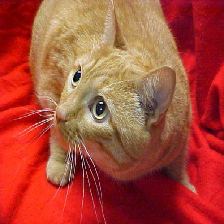

In [10]:
img